In [1]:
import pandas as pd
import numpy as np
import os
from glob import glob
from sklearn.metrics import roc_curve, auc, balanced_accuracy_score
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

In [2]:
#========== FUNCTIONS TO PRINT SCORES ==========#

def compute_metrics(labels, pred):
    
    fpr, tpr, thres = roc_curve(labels, pred)
    rocauc = auc(fpr, tpr)
    fnr = 1 - tpr
    eer = fpr[np.nanargmin(np.absolute(fnr - fpr))]
    
    #optimal_index = np.argmax(tpr - fpr)
    #optimal_threshold = thres[optimal_index]

    binary_pred = np.where(pred < -0.5, 0, 1)    
    acc = balanced_accuracy_score(labels, binary_pred)
    
    return rocauc, eer, acc
    
def printmd(string):
    display(Markdown(string))

def print_results(model_names, dataset_list):
    if isinstance(model_names, str):
        model_names = [model_names]

    all_scores = {}

    for dataset in dataset_list:
        dataset_name = os.path.basename(dataset)
        output = f"### {dataset_name.upper()} DATASET\n\n"
        scores = []

        for model_name in model_names:
            result_list = glob(os.path.join(dataset, f"{model_name}.txt"))

            for result in result_list:
                df = pd.read_csv(result, header=None, sep=' ')
                df = df.rename(columns={0: 'path', 1: 'score', 2: 'label'})

                rocauc, eer, bal_acc = compute_metrics(df['label'], df['score']) 

                exp_name = os.path.basename(result)[:-4]
                scores.append({
                    'name': exp_name,
                    'auc': rocauc,
                    'eer': eer,
                    'bal_acc': bal_acc
                })

                if exp_name not in all_scores:
                    all_scores[exp_name] = []
                all_scores[exp_name].append({
                    'dataset': dataset_name,
                    'auc': rocauc,
                    'eer': eer,
                    'bal_acc': bal_acc
                })

        # Best scores
        best_auc = max(scores, key=lambda x: x['auc'])['auc']
        best_eer = min(scores, key=lambda x: x['eer'])['eer']
        best_bal_acc = max(scores, key=lambda x: x['bal_acc'])['bal_acc']

        for s in scores:
            name = s['name']
            auc = s['auc']
            eer = s['eer']
            bal_acc = s['bal_acc']

            auc_str = f"**{auc*100:.2f}**" if auc == best_auc else f"{auc*100:.2f}"
            eer_str = f"**{eer*100:.2f}**" if eer == best_eer else f"{eer*100:.2f}"
            bal_str = f"**{bal_acc*100:.2f}**" if bal_acc == best_bal_acc else f"{bal_acc*100:.2f}"

            output += f"`{name}`\t AUC: {auc_str} \t EER: {eer_str} \t Balanced Acc: {bal_str}\n\n"

        printmd(output)

    return all_scores
        
def print_results_NO_BACC(model_names, dataset_list):
    if isinstance(model_names, str):
        model_names = [model_names]

    #dataset_list = glob('/nas/home/vnegroni/ispl_safe/results/*')
    all_scores = {}  # Store results in a dictionary

    for dataset in dataset_list:
        dataset_name = os.path.basename(dataset)
        output = f"### {dataset_name.upper()} DATASET\n\n"
        scores = []

        for model_name in model_names:
            result_list = glob(os.path.join(dataset, f"{model_name}.txt"))

            for result in result_list:
                df = pd.read_csv(result, header=None, sep=' ')
                df = df.rename(columns={0: 'path', 1: 'score', 2: 'label'})

                rocauc, eer, bal_acc = compute_metrics(df['label'], df['score'])

                exp_name = os.path.basename(result)[:-4]
                scores.append({
                    'name': exp_name,
                    'auc': rocauc,
                    'eer': eer
                })

                # Save to the main dictionary
                if exp_name not in all_scores:
                    all_scores[exp_name] = []
                all_scores[exp_name].append({
                    'dataset': dataset_name,
                    'auc': rocauc,
                    'eer': eer
                })

        best_auc = max(scores, key=lambda x: x['auc'])['auc']
        best_eer = min(scores, key=lambda x: x['eer'])['eer']

        for s in scores:
            name = s['name']
            auc = s['auc']
            eer = s['eer']

            auc_str = f"**{auc*100:.2f}**" if auc == best_auc else f"{auc*100:.2f}"
            eer_str = f"**{eer*100:.2f}**" if eer == best_eer else f"{eer*100:.2f}"

            output += f"`{name}`\t AUC: {auc_str} \t EER: {eer_str}\n\n"

        printmd(output)

    return all_scores


def print_average_results_by_type(all_scores, known_datasets, subset='overall'):
    if subset not in ('known', 'unknown', 'overall'):
        raise ValueError("subset must be 'known', 'unknown', or 'overall'")

    output = f"## AVERAGE METRICS - {subset.upper()}\n\n"
    avg_scores = []

    for model, entries in all_scores.items():
        if subset == 'known':
            filtered = [e for e in entries if e['dataset'] in known_datasets]
        elif subset == 'unknown':
            filtered = [e for e in entries if e['dataset'] not in known_datasets]
        else:
            filtered = entries

        aucs = [e['auc'] for e in filtered]
        eers = [e['eer'] for e in filtered]
        bals = [e['bal_acc'] for e in filtered]

        avg_auc = np.mean(aucs) if aucs else None
        avg_eer = np.mean(eers) if eers else None
        avg_bal = np.mean(bals) if bals else None

        avg_scores.append({
            'model': model,
            'avg_auc': avg_auc,
            'avg_eer': avg_eer,
            'avg_bal': avg_bal
        })

    # Best values
    best_auc = max((s['avg_auc'] for s in avg_scores if s['avg_auc'] is not None), default=None)
    best_eer = min((s['avg_eer'] for s in avg_scores if s['avg_eer'] is not None), default=None)
    best_bal = max((s['avg_bal'] for s in avg_scores if s['avg_bal'] is not None), default=None)

    def fmt(value, best_value, is_best_fmt=True):
        if value is None:
            return "N/A"
        s = f"{value*100:.2f}"
        return f"**{s}**" if is_best_fmt and value == best_value else s

    for s in avg_scores:
        model = s['model']
        auc_str = fmt(s['avg_auc'], best_auc)
        eer_str = fmt(s['avg_eer'], best_eer)
        bal_str = fmt(s['avg_bal'], best_bal)

        output += f"`{model}`\t Avg AUC: {auc_str} \t Avg EER: {eer_str} \t Avg Balanced Acc: {bal_str}\n\n"

    printmd(output)

    
def print_average_results_by_type_NO_BACC(all_scores, known_datasets, subset='overall'):
    """
    subset: one of 'known', 'unknown', 'overall'
    """

    if subset not in ('known', 'unknown', 'overall'):
        raise ValueError("subset must be 'known', 'unknown', or 'overall'")

    output = f"## AVERAGE METRICS - {subset.upper()}\n\n"
    avg_scores = []

    for model, entries in all_scores.items():
        # Filter by subset
        if subset == 'known':
            filtered = [e for e in entries if e['dataset'] in known_datasets]
        elif subset == 'unknown':
            filtered = [e for e in entries if e['dataset'] not in known_datasets]
        else:  # overall
            filtered = entries

        aucs = [e['auc'] for e in filtered]
        eers = [e['eer'] for e in filtered]

        if not aucs:
            avg_auc = None
            avg_eer = None
        else:
            avg_auc = np.mean(aucs)
            avg_eer = np.mean(eers)

        avg_scores.append({
            'model': model,
            'avg_auc': avg_auc,
            'avg_eer': avg_eer
        })

    # Get best scores for formatting (highest AUC, lowest EER)
    best_auc = max((s['avg_auc'] for s in avg_scores if s['avg_auc'] is not None), default=None)
    best_eer = min((s['avg_eer'] for s in avg_scores if s['avg_eer'] is not None), default=None)

    def fmt(value, best_value, is_best_fmt=True):
        if value is None:
            return "N/A"
        s = f"{value*100:.2f}"
        return f"**{s}**" if is_best_fmt and value == best_value else s

    for s in avg_scores:
        model = s['model']
        auc_str = fmt(s['avg_auc'], best_auc)
        eer_str = fmt(s['avg_eer'], best_eer, is_best_fmt=True)

        output += f"`{model}`\t Avg AUC: {auc_str} \t Avg EER: {eer_str}\n\n"

    printmd(output)

In [64]:
def plot_5_expert_weights_row(rootpath,
                              model_name,
                              gen_id,
                              expert_labels=None):

    # Build file paths dynamically
    global_path = os.path.join(
        rootpath,
        f"{model_name}_{gen_id}_gating_mean_global.npy"
    )

    real_path = os.path.join(
        rootpath,
        f"{model_name}_{gen_id}_gating_mean_real.npy"
    )

    spoof_path = os.path.join(
        rootpath,
        f"{model_name}_{gen_id}_gating_mean_fake.npy"
    )

    # Load weights
    global_w = np.load(global_path).flatten()
    real_w   = np.load(real_path).flatten()
    spoof_w  = np.load(spoof_path).flatten()

    # Basic check
    for name, w in zip(["Global", "Real", "Spoof"],
                       [global_w, real_w, spoof_w]):
        if len(w) != 5:
            print(f"[WARN] {name}: Expected 5 experts, got {len(w)}")

    if expert_labels is None:
        expert_labels = [f"E{i}" for i in range(len(global_w))]

    # Create 1x3 layout
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

    titles = ["Avg global weights", "Avg weights for real data", "Avg weights for fake data"]
    colors = ["blue", "pink", "green"]
    data   = [global_w, real_w, spoof_w]

    for ax, weights, title, color in zip(axes, data, titles, colors):
        ax.bar(range(len(weights)), weights, color=color)
        ax.set_title(f"{title}")
        ax.set_xticks(range(len(weights)))
        ax.set_xticklabels(expert_labels, rotation=45)
        ax.set_ylim(0, 1)
        ax.grid(True)
        ax.set_axisbelow(True)

    axes[0].set_ylabel("Avg Gating Weight")

    plt.tight_layout()
    plt.show()


Since from the table in Notion emerged that on all ASVspoof2012 pure TTS systems there is at least an expert that performs good (even though not supposed too, **ISSUE 1**), I think it makes sense to test the MoE on every single generator.  
Ideally we would expect performances > than random guess everywhere.  
Yet...     

Weights for real data are consistent with the behavior observed during sanity checks (see below these tests). This is ok.   
However the weights assigned to experts, when spoofed data is fed to the MoE, replicate basically the same trend: the gate thinks that most of them are real (see mean scores for fake data and AUC/EER values), this is **ISSUE 2**.  

I therefore see 2 distict things to fix here:
- **ISSUE 1**: experts not behaving as expected (see Notion table)  
- **ISSUE 2**: This gate learning issue (hopefully it is related to how I weight the 3 training losses)  
  
Am I missing other major problems?    

# Evaluate MoE: performance + expert weighting

In [46]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/MoE/TargetCheck"
model_name= "moe_first_trial_5_experts"

## Test MoE on 1 generator at a time

10 TTS generators from ASVspoof 2019 -> 10 tests  
  
---  
  
1000 real samples  
1000 deepfake samples  

--- 

TOTAL: 2000 samples per test   

### A01 
Target for: OVERSMOOTHING, MONOTONIC SPEECH  
  
Mean score (fake=1): 0.080625  
Mean score (real=0): 0.026125  
  
AUC: 46.14%, EER: 53.13%  

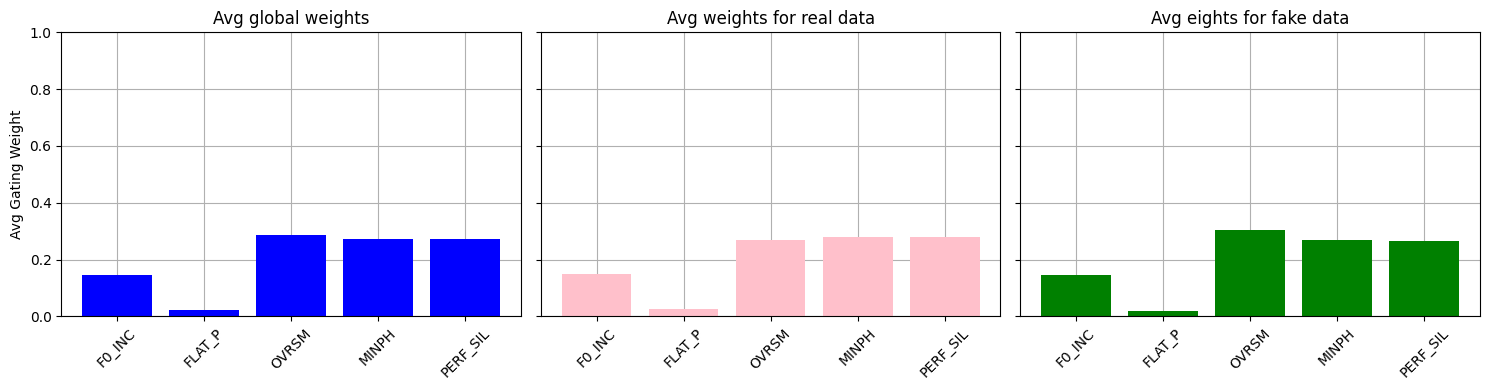

In [47]:
plot_5_expert_weights_row(rootpath, model_name, "A01", expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL'])

### A02 
Target for: -  
  
Mean score (fake=1): 0.072745  
Mean score (real=0): 0.026124  
  
AUC: 44.60%, EER: 56.00%    

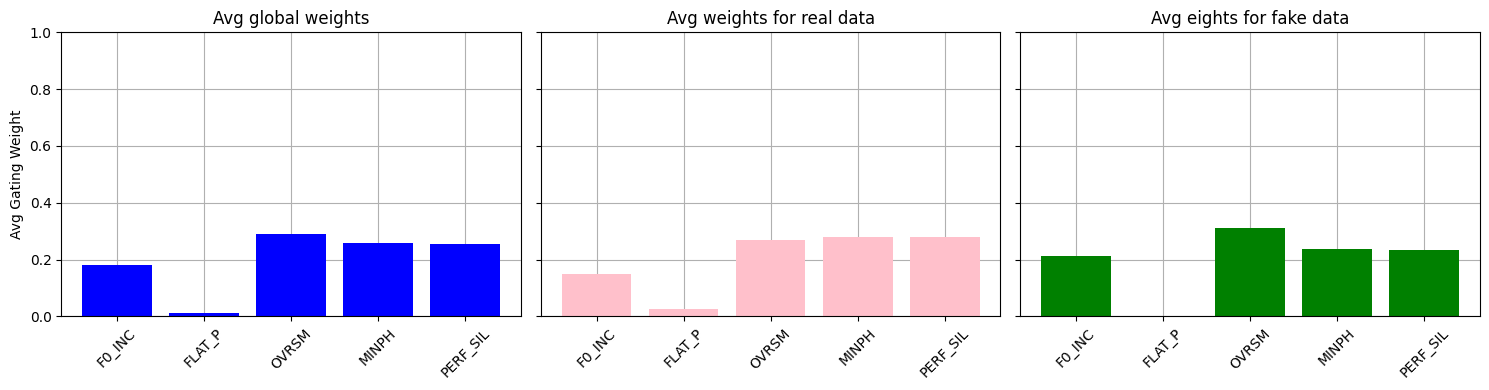

In [48]:
plot_5_expert_weights_row(rootpath, model_name, "A02", expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL'])

### A03
Target for: -  
  
Mean score (fake=1): 0.076363  
Mean score (real=0): 0.026125  
  
AUC: 49.11%, EER: 51.75%    

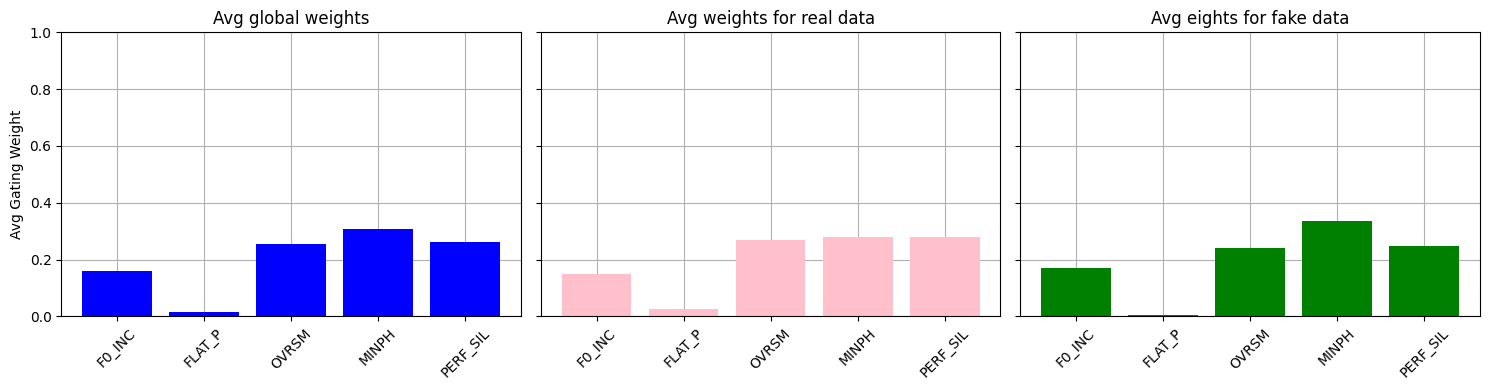

In [49]:
plot_5_expert_weights_row(rootpath, model_name, "A03", expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL'])

### A04
Target for: F0 INCONSISTENCY  

Mean score (fake=1): 0.077555  
Mean score (real=0): 0.026125  
  
AUC: 63.90%, EER: 40.81%    

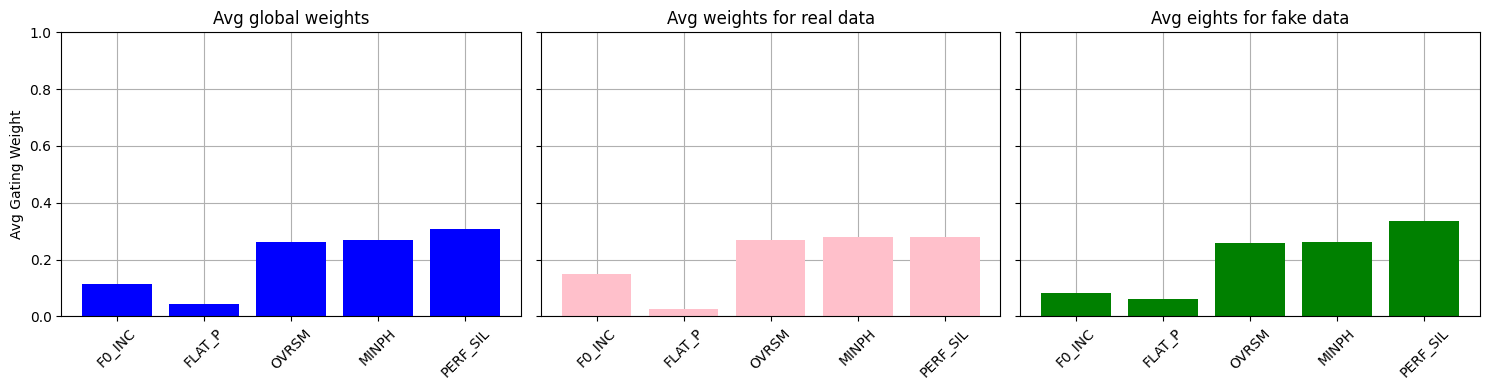

In [50]:
plot_5_expert_weights_row(rootpath, model_name, "A04", expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL'])

### A07  
Target for: -
  
Mean score (fake=1): 0.025133  
Mean score (real=0): 0.026125  
  
AUC: 28.05%, EER: 69.50%  

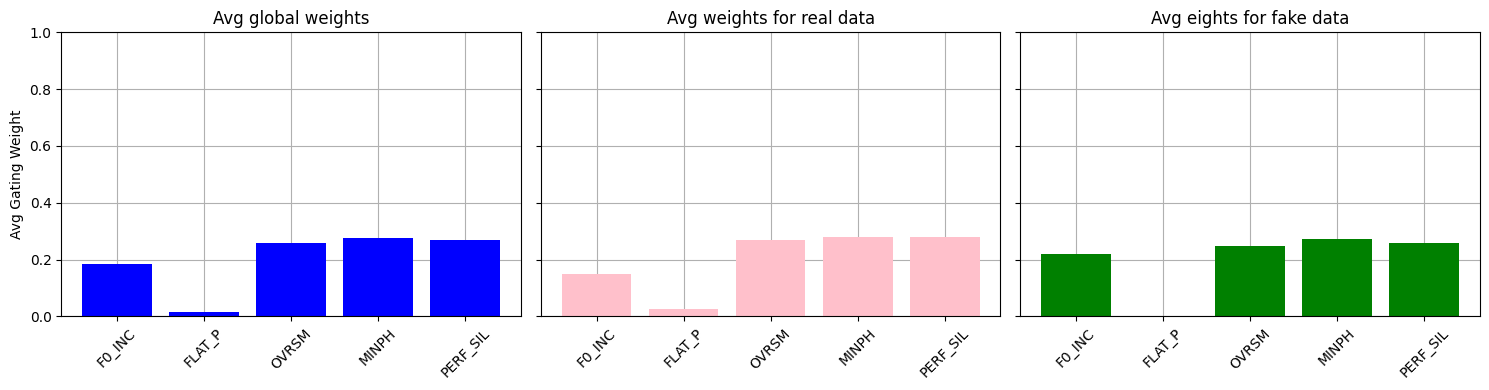

In [51]:
plot_5_expert_weights_row(rootpath, model_name, "A07", expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL'])

### A08
Target for: PERFECT SILENCE
  
Mean score (fake=1): 0.111928  
Mean score (real=0): 0.026124  
  
AUC: 41.21%, EER: 58.66%  

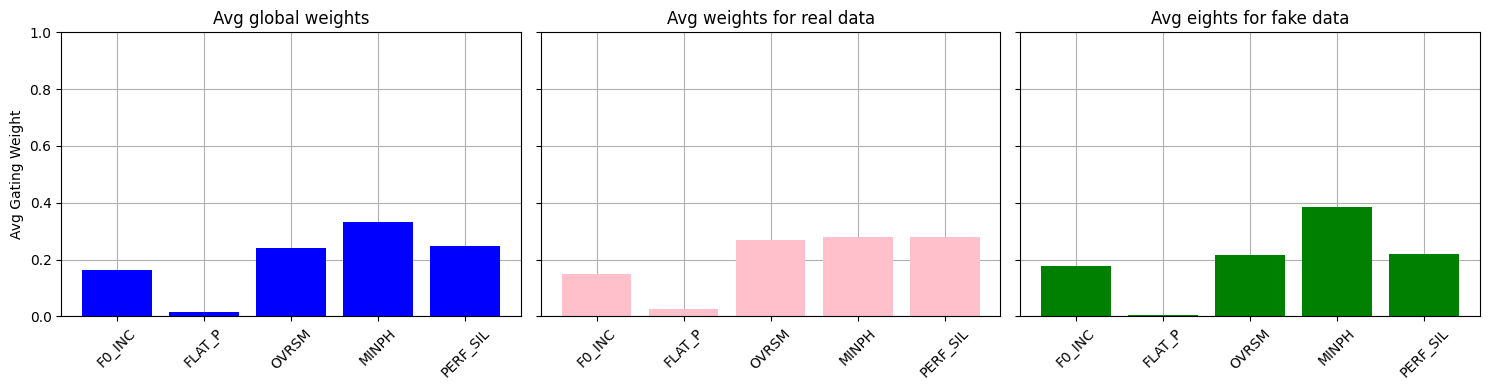

In [52]:
plot_5_expert_weights_row(rootpath, model_name, "A08", expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL'])

### A09
Target for: MINIMUM PHASE
  
Mean score (fake=1): 0.547557  
Mean score (real=0): 0.026125  
  
AUC: 85.59%, EER: 20.72%  

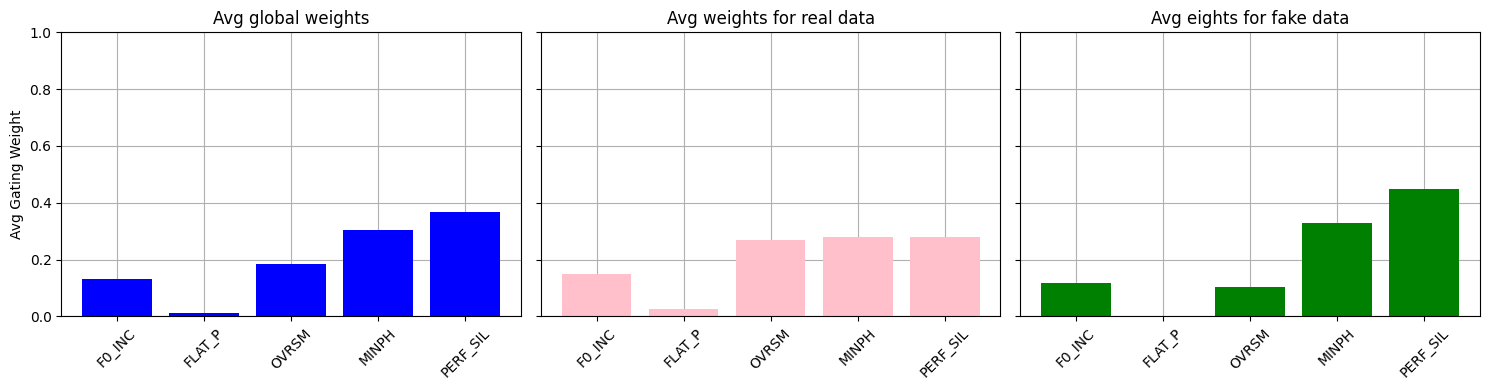

In [55]:
plot_5_expert_weights_row(rootpath, model_name, "A09", expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL'])

### A10
Target for: - 
  
Mean score (fake=1): 0.024986  
Mean score (real=0): 0.026125  
  
AUC: 41.28%, EER: 56.64%  

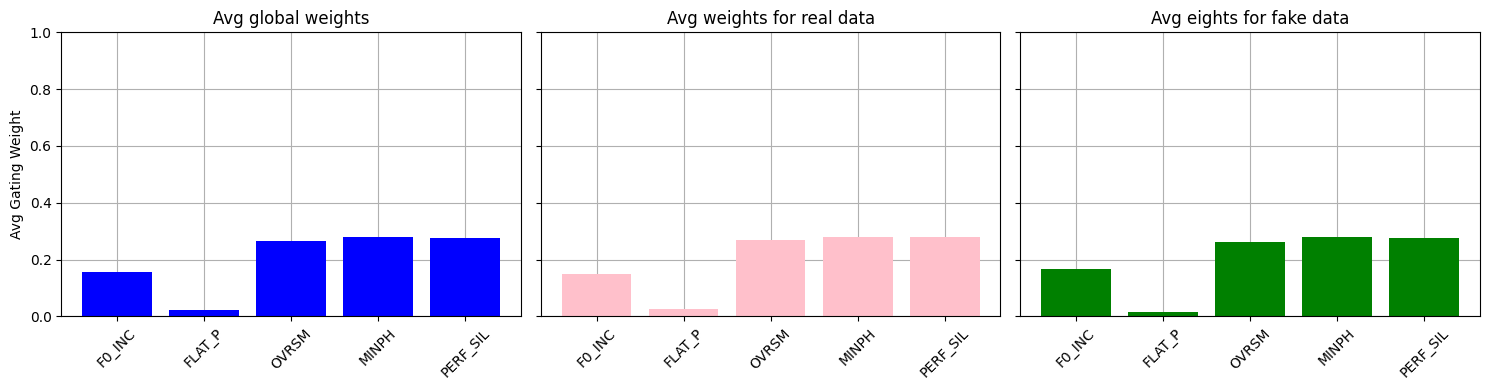

In [54]:
plot_5_expert_weights_row(rootpath, model_name, "A10", expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL'])

### A11
Target for: -  
  
Mean score (fake=1): 0.030911  
Mean score (real=0): 0.026125  
  
AUC: 41.10%, EER: 56.96%  

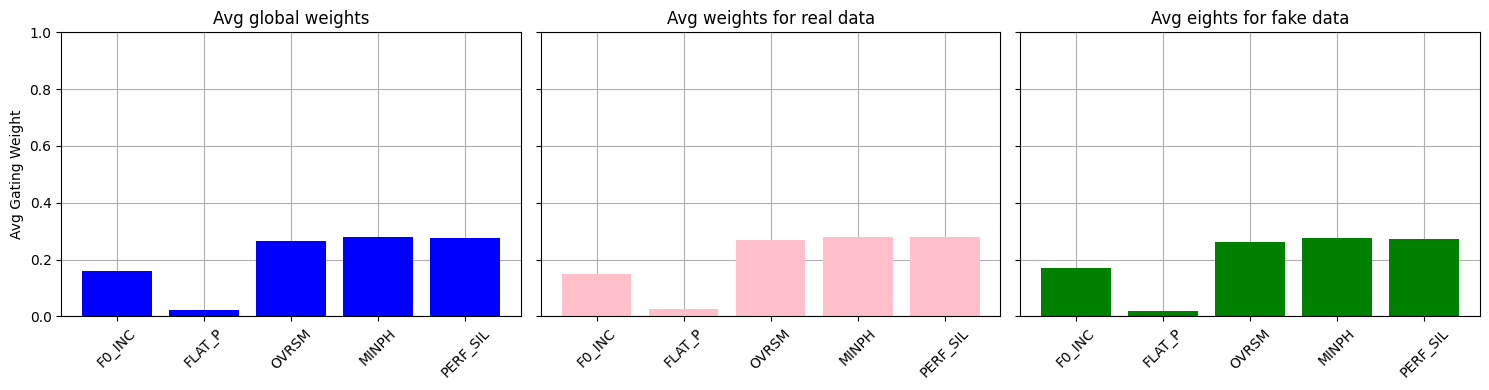

In [56]:
plot_5_expert_weights_row(rootpath, model_name, "A11", expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL'])

### A12
Target for: - 
  
Mean score (fake=1): 0.132581  
Mean score (real=0): 0.026125  
  
AUC: 50.82%, EER: 50.27%  

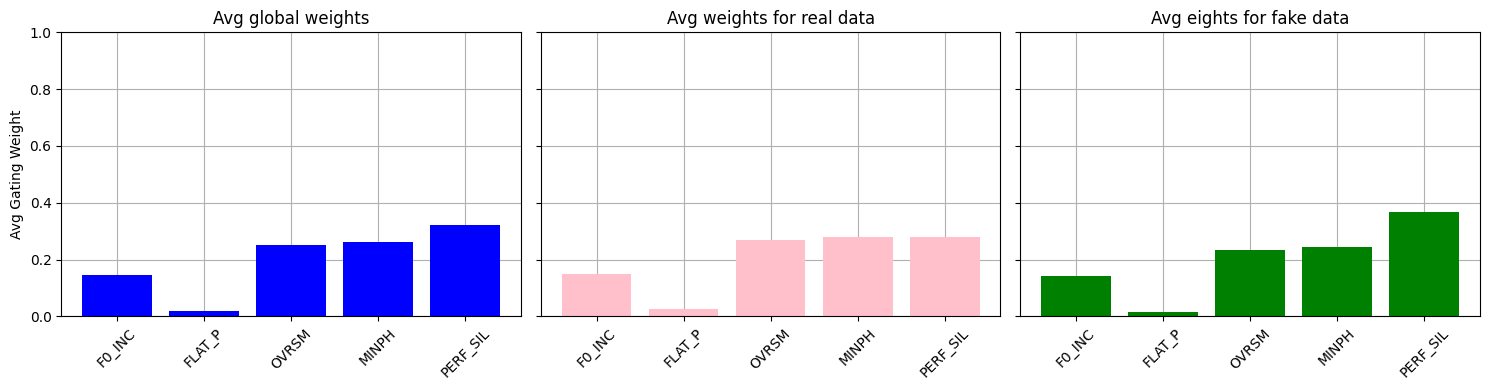

In [57]:
plot_5_expert_weights_row(rootpath, model_name, "A12", expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL'])

## Test MoE on all generators together

10 TTS generators from ASVspoof 2019 -> 1 tests  
  
---  
  
~12000 real samples (all)  
15000 deepfake samples  

--- 

TOTAL: ~27000 samples  

---  

**Results:** AUC: **49.00%**, EER: **51.71%**  

## Test MoE on [A01 A03 A04 A09]
Basically what I previously though being the targets..  
  
Mean score (fake=1): 0.211278  
Mean score (real=0): 0.032950  
  
AUC: **60.55%**, EER: **43.71%**

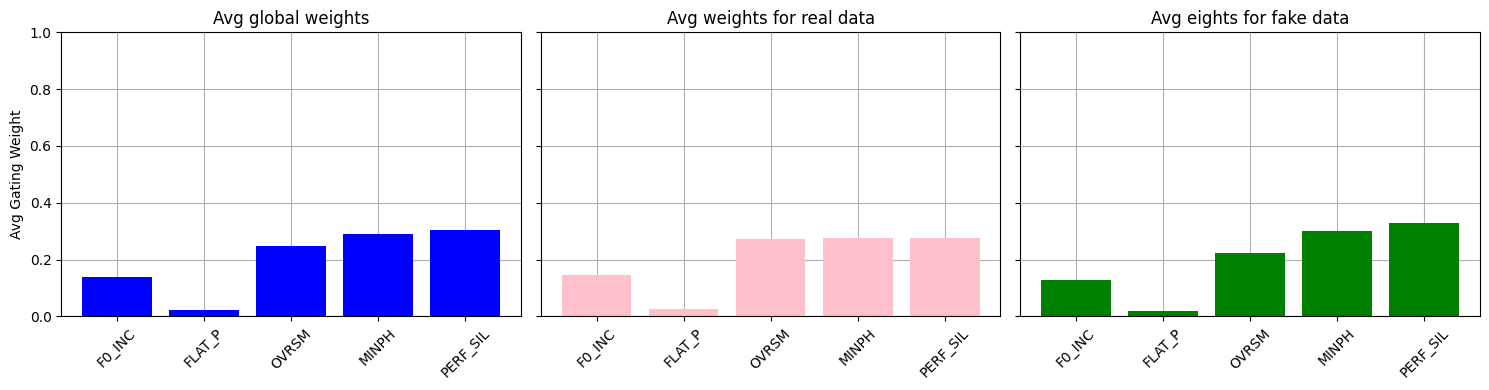

In [59]:
plot_5_expert_weights_row(rootpath, model_name, "ALL", expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL'])

## Test MoE on [A01 A04 A08 A09]
What seems to be the actual targets from the table...    
  
Mean score (fake=1): 0.217909  
Mean score (real=0): 0.032950    
  
AUC: **59.41%**, EER: **44.38%**

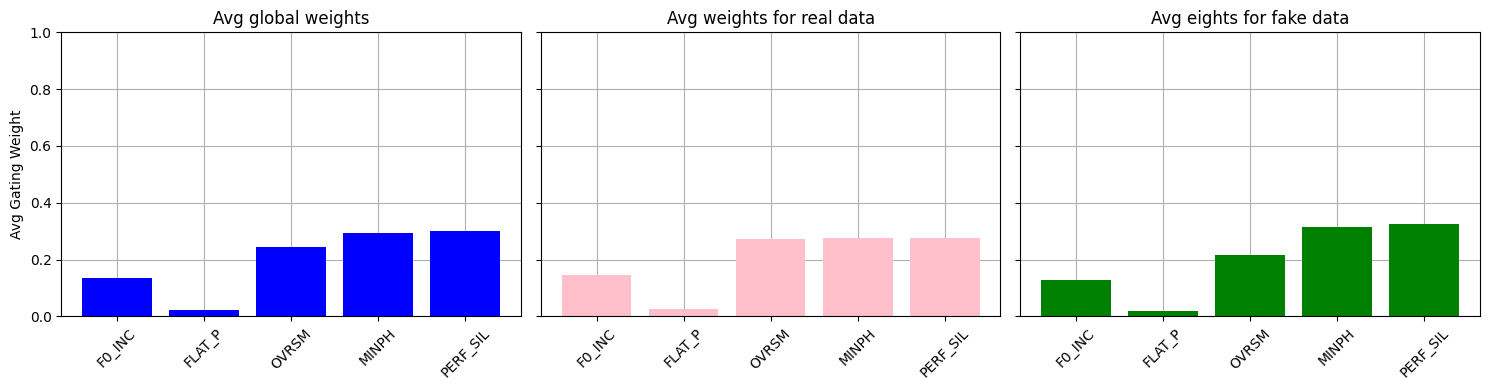

In [60]:
plot_5_expert_weights_row(rootpath, model_name, "ALL_NEW", expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL'])

# Sanity Checks

In [62]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/MoE/SanityCheck"

## All manipulations applied  

1000 real + 1000 manipulated data (from EVAL SET)  
Fakes are fakes for every expert (= every feature is manipulated) -> would expect equal contribution also on fake data  
Yet...  

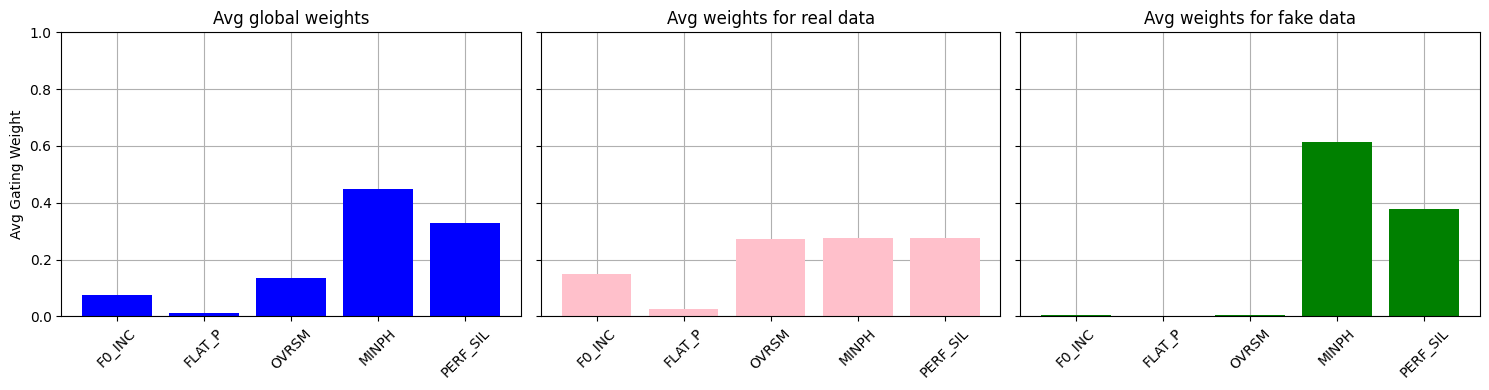

In [66]:
# Mean score (fake=1): 0.646014
# Mean score (real=0): 0.036437
# AUC: 99.10%, EER: 2.37%

plot_5_expert_weights_row(rootpath, model_name, "ALL", expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL'])

## One manipulation at a time

### F0 Inconsistency

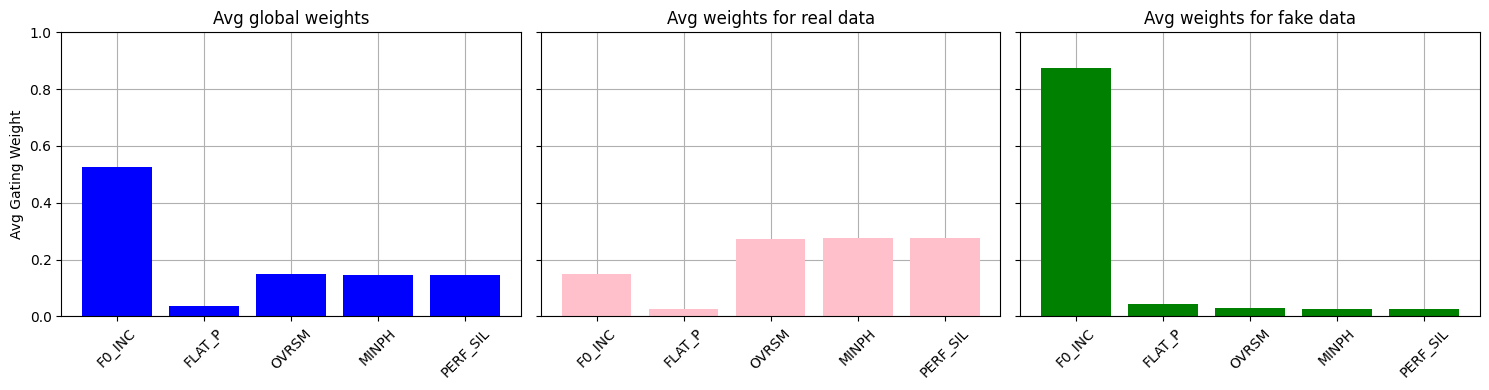

In [67]:
# Mean score (fake=1): 0.808270
# Mean score (real=0): 0.036436

# AUC: 98.90%, EER: 3.99%

plot_5_expert_weights_row(rootpath, model_name, "F0_INCONS", expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL'])

### Flat Pitch

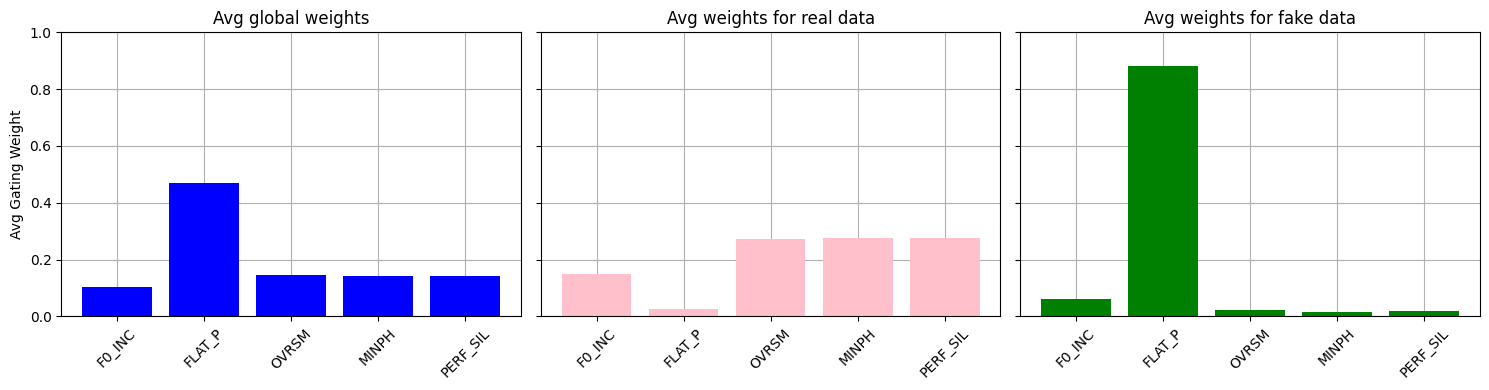

In [68]:
# Mean score (fake=1): 0.858970
# Mean score (real=0): 0.036437

# AUC: 99.46%, EER: 2.37%

plot_5_expert_weights_row(rootpath, model_name, "FLAT_PITCH", expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL'])

### Oversmoothing

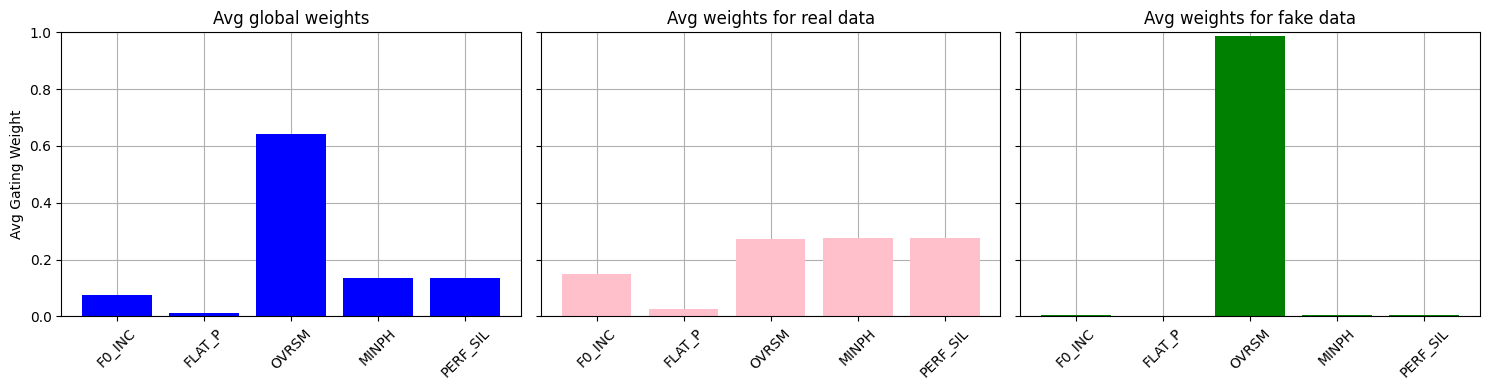

In [69]:
# Mean score (fake=1): 0.979713
# Mean score (real=0): 0.036437

# AUC: 99.91%, EER: 1.19%

plot_5_expert_weights_row(rootpath, model_name, "OVERSMOOTH", expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL'])

### Minimum Phase

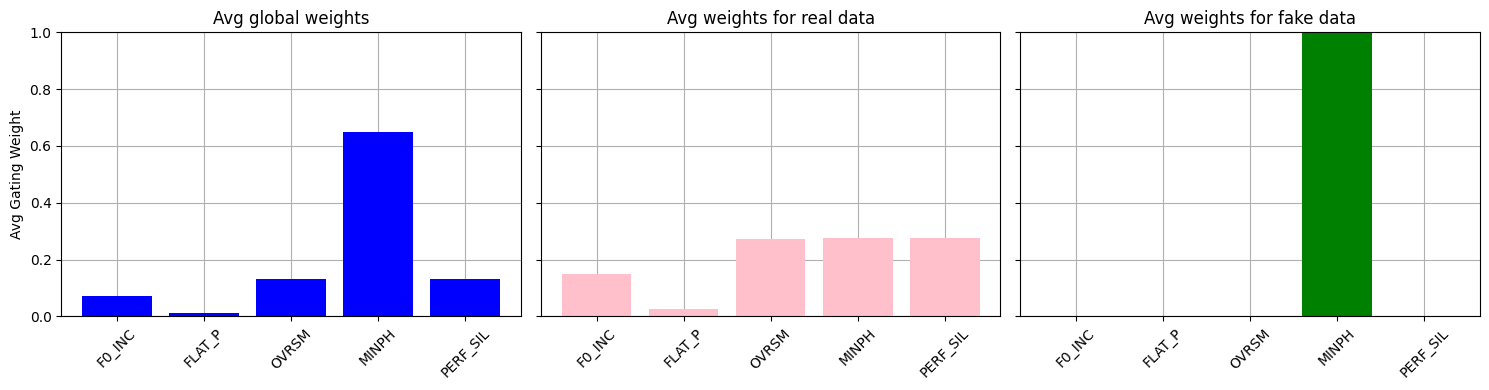

In [72]:
# Mean score (fake=1): 0.999766
# Mean score (real=0): 0.036437

# AUC: 100.00%, EER: 0.22%

plot_5_expert_weights_row(rootpath, model_name, "MIN_PHASE", expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL'])

### Perfect Silences

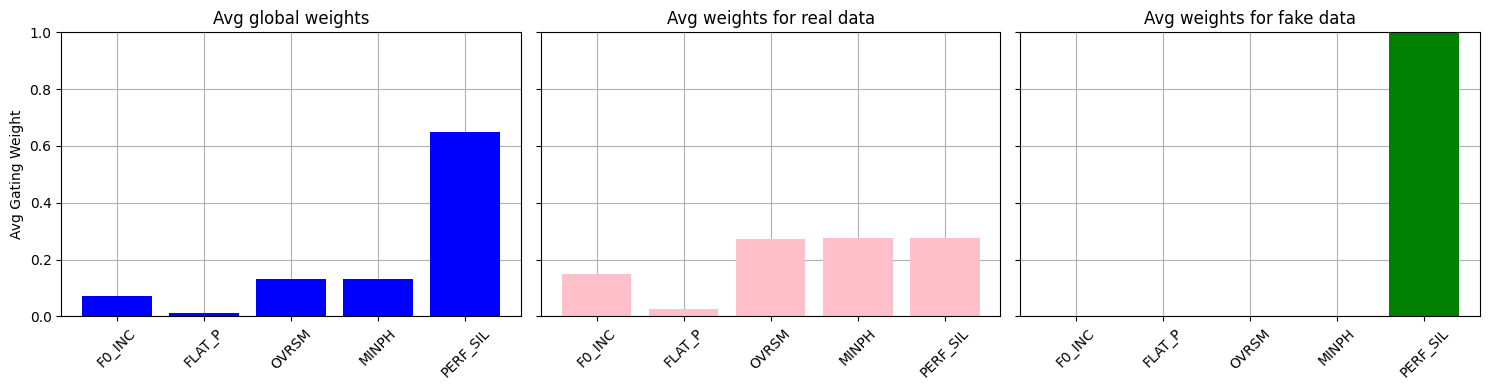

In [71]:
# Mean score (fake=1): 0.999303
# Mean score (real=0): 0.036437

# AUC: 99.99%, EER: 0.22%

plot_5_expert_weights_row(rootpath, model_name, "PERF_SIL", expert_labels=['F0_INC', 'FLAT_P', 'OVRSM', 'MINPH', 'PERF_SIL'])